In [1]:
"""
GOAL: compare how well the ISI-based change point methods (llr_pair, edivisive, ks, npid)
recover the true change point time: L2 error and minimum step height for L2 < threshold.
"""

'\nGOAL: compare how well the ISI-based change point methods (llr_pair, edivisive, ks, npid)\nrecover the true change point time: L2 error and minimum step height for L2 < threshold.\n'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *

In [3]:
tag = 'N250'
SAVE = False
with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    true_cp = pickle.load(file)['changepoint']   # ms, relative to the saved spike times (includes any warm-up)

files = {'llr_pair':  f'CPA_cusum_mean_{tag}_llr_pair.pickle',
         'edivisive': f'CPA_cusum_mean_{tag}_edivisive_isi.pickle',
         'ks':        f'CPA_cusum_mean_{tag}_ks.pickle',
         'npid':      f'CPA_cusum_mean_{tag}_npid.pickle'}
methods = list(files)

data = {}
for m, p in files.items():
    with open(p, 'rb') as file:
        data[m] = pickle.load(file)
norms = {m: cp_error_norms(d, true_cp) for m, d in data.items()}

all_data = pd.concat(data.values())
# descending f so f = 0 (darkest) is drawn last, on top
f_order = np.sort(all_data['autapse f'].unique())[::-1].tolist()
f_lim = dict(vmin = all_data['autapse f'].min(), vmax = all_data['autapse f'].max())
variances = np.sort(all_data['variance'].unique())
print(f"methods: {methods}\nf: {len(f_order)}  var: {len(variances)}  N: {all_data['N'].nunique()}")

methods: ['llr_pair', 'edivisive', 'ks', 'npid']
f: 32  var: 4  N: 250


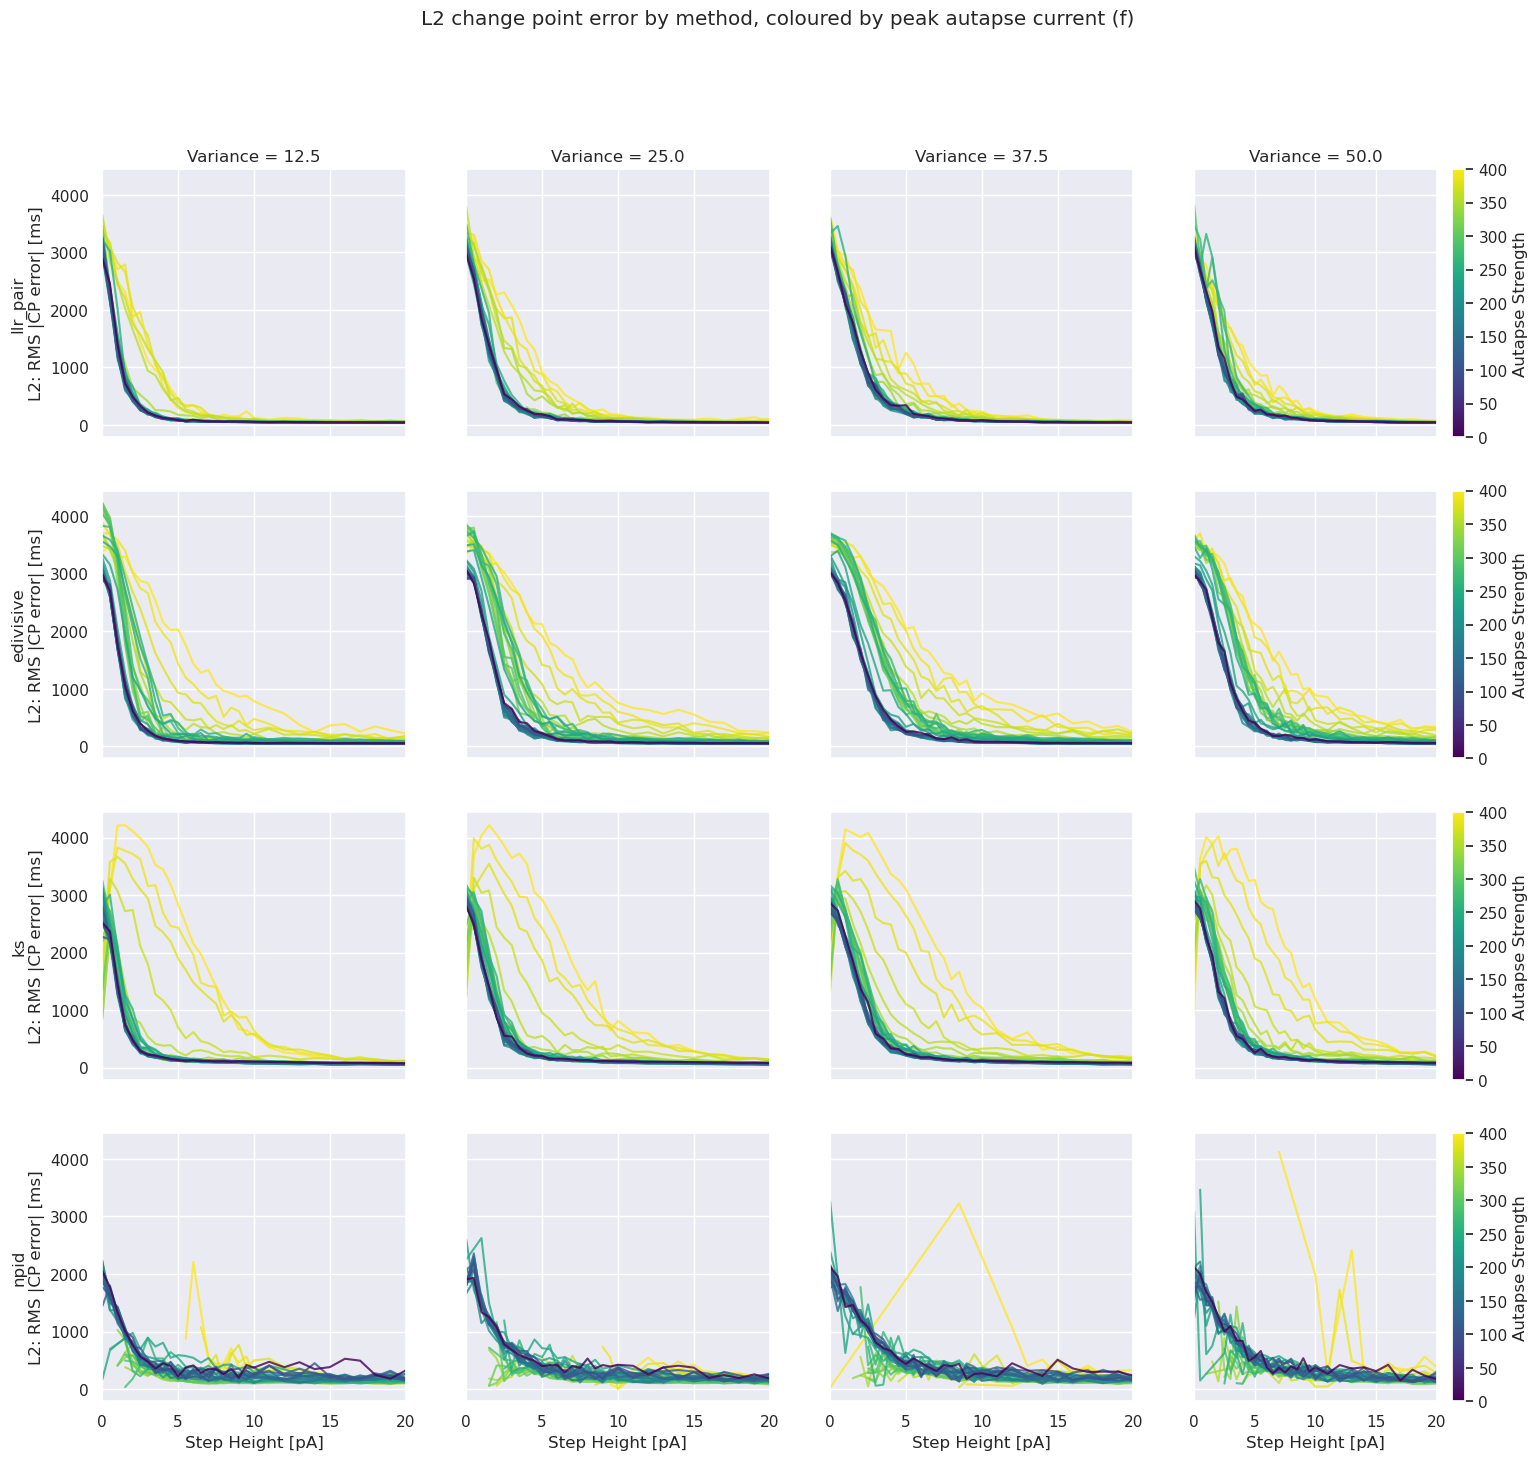

In [4]:
''' L2 NORM CHANGE POINT ERROR, one row per method '''
# L2 = sqrt(mean(|CP - true_cp|**2)) per condition (pooled over N)
fig, ax = plt.subplots(len(methods), len(variances), figsize = (18, 4 * len(methods)),
                       sharey = True, sharex = True, squeeze = False)
for r, m in enumerate(methods):
    for n, v in enumerate(variances):
        df = norms[m][norms[m]['variance'] == v]
        fig, ax[r, n] = psychometric_curve(df, x = 'step_height', y = 'L2 |error|', hue = 'autapse f', hue_order = f_order,
                                           fig = fig, ax = ax[r, n], add_colorbar = (n == len(variances) - 1))
        ax[r, n].set_xlim((0, 20))
        ax[r, n].set_ylabel(f'{m}\nL2: RMS |CP error| [ms]' if n == 0 else '')
        if r == 0: ax[r, n].set_title(f'Variance = {v}')
        ax[r, n].set_xlabel('Step Height [pA]' if r == len(methods) - 1 else '')
fig.suptitle('L2 change point error by method, coloured by peak autapse current (f)')
if SAVE: plt.savefig(f'./plots/{tag}_ISI_methods_L2.png', bbox_inches = 'tight')
plt.show()

WARNING    /home/liam/Documents/PhD_autapses/AQUA_project/changepoint_analysis/CP_functions.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return norms.groupby(list(group_cols)).apply(first_step).rename(step_col).reset_index()
 [py.warnings]
WARNING    /home/liam/Documents/PhD_autapses/AQUA_project/changepoint_analysis/CP_functions.py:261: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return norms.groupby(list

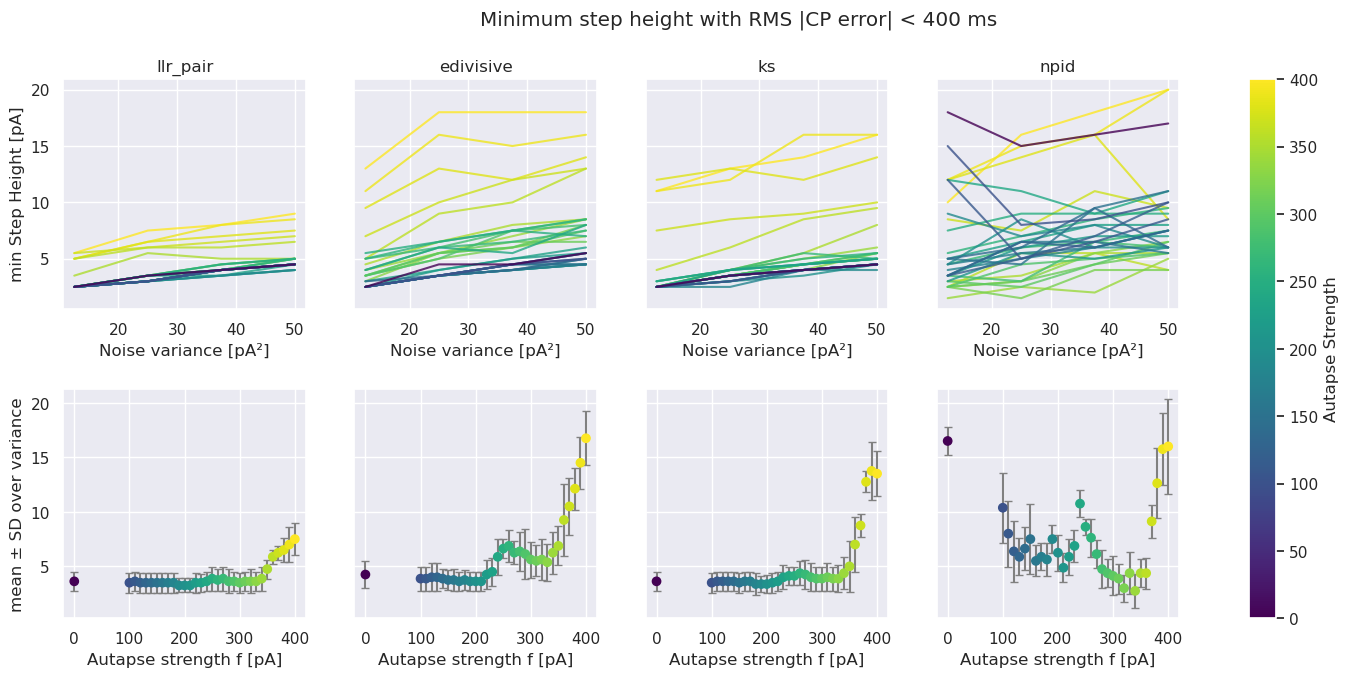

In [5]:
''' MINIMUM STEP HEIGHT FOR L2 < THRESHOLD, one column per method '''
# per f and variance: smallest step h > 0 from which L2 stays below the threshold for every larger h
# (NaN = never). Bottom row: each curve's mean ± SD over variance (NaNs skipped)
L2_THR = 400    # ms

fig, ax = plt.subplots(2, len(methods), figsize = (4.5 * len(methods), 7), sharex = 'row', sharey = 'row')
fig.subplots_adjust(hspace = 0.35)
for c, m in enumerate(methods):
    h_min = min_step_below(norms[m], L2_THR)
    fig, ax[0, c] = psychometric_curve(h_min, x = 'variance', y = 'step_height', hue_order = f_order,
                                       fig = fig, ax = ax[0, c], add_colorbar = False)
    ax[0, c].set_title(m)
    ax[0, c].set_xlabel('Noise variance [pA²]')
    ax[0, c].set_ylabel('min Step Height [pA]' if c == 0 else '')

    avg = h_min.groupby('autapse f')['step_height'].agg(['mean', 'std'])
    ax[1, c].errorbar(avg.index, avg['mean'], yerr = avg['std'], fmt = 'none', ecolor = 'grey', capsize = 3, zorder = 2)
    sc = ax[1, c].scatter(avg.index, avg['mean'], c = avg.index, cmap = 'viridis', **f_lim, zorder = 3)
    ax[1, c].set_xlabel('Autapse strength f [pA]')
    ax[1, c].set_ylabel('mean ± SD over variance' if c == 0 else '')
fig.colorbar(sc, ax = ax, label = 'Autapse Strength')
fig.suptitle(f'Minimum step height with RMS |CP error| < {L2_THR} ms')
if SAVE: plt.savefig(f'./plots/{tag}_ISI_methods_min_step_L2_{L2_THR}.png', bbox_inches = 'tight')
plt.show()